# Compare results across assays

This notebook calculates:
- Overlap of alleles and genes with results across three measured assays
- Distribution of ClinVar categories across three assays
- Comparison of actual readouts across assays
- Comparison of measured assays to the AI scores
- Comparison of assay readouts to the sequence features (plDDT and RSA)

In [ ]:
import polars as pl
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import pearsonr
from matplotlib_venn import venn3
import numpy as np 
import matplotlib.colors as colors

In [42]:
inputs_dir = "../1_inputs"
outputs_dir = "../3_outputs"
metadata_outputs = "../../1_allele_collection/3_outputs"

## Process assay results

In [43]:
abun = pl.read_csv(f"{inputs_dir}/abun_scores.csv").select(["orf_id", "mut_id", "zscore_log2"]).unique().rename({
    "zscore_log2": "abun_score"
})
misloc = pl.read_csv(f"{inputs_dir}/misloc_scores.csv").select(["allele_0", "mean_auroc"]).unique().rename({
    "mean_auroc": "misloc_score"
})
ppi = pl.read_csv(f"{inputs_dir}/ppi_scores.csv").select(["orf_id", "mut_id", "normalized_distance"]).unique().rename({
    "normalized_distance": "ppi_score"
})

In [44]:
# process metadata
metadata = pl.DataFrame(pd.read_csv(f"{metadata_outputs}/varchamp_consolidated_alleles_clinvar_gnomad.tsv", sep="\t"))
mut_cols = ["mutation_id_rc4", "mutation_id_cegs2", "mutation_id_edgotyping3"]
id_vars = [col for col in metadata.columns if col not in mut_cols]
metadata = metadata.unpivot(index=id_vars, 
                            on=mut_cols,
                            variable_name="mutation_collection",
                            value_name="mut_id")

priority_col = ["orf_id", "mut_id", "symbol", "aa_change", "ensembl_gene_id", "clinvar_clnsig_clean", "gnomad_af", "StarStatus"]
metadata = metadata.select(priority_col).filter(~pl.col("mut_id").is_null()).with_columns(
    pl.col("mut_id").cast(pl.Int64).alias("mut_id"),
    pl.col("orf_id").cast(pl.Int64).alias("orf_id"),
    pl.concat_str([pl.col("symbol"), pl.col("aa_change")], separator="_").alias("allele_0")
)

In [67]:
# merge all scores
scores = metadata.join(abun, on=["orf_id", "mut_id"], how="left")
scores = scores.join(misloc, on="allele_0", how="left")
scores = scores.join(ppi, on=["orf_id", "mut_id"], how="left")

# Get rid of duplicates
scores = scores.drop(["orf_id", "mut_id"])
scores = scores.unique()

# Keep only alleles with at least one score
scores = scores.filter(
    ~(pl.col("abun_score").is_null() & pl.col("ppi_score").is_null() & pl.col("misloc_score").is_null())
)

scores.select(["symbol", "aa_change"]).unique().shape

(1309, 2)

## Calculate overlaps across assays

We profiled this many alleles in each assay: 919 for abundance, 603 for mislocalization, and 701 for ppi.


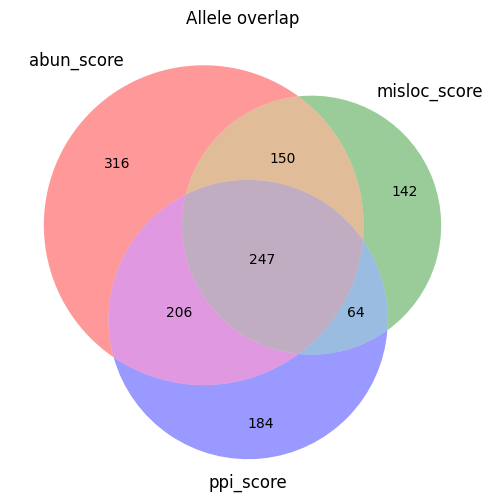

We profiled this many genes in each assay: 92 for abundance, 111 for mislocalization, and 84 for ppi.


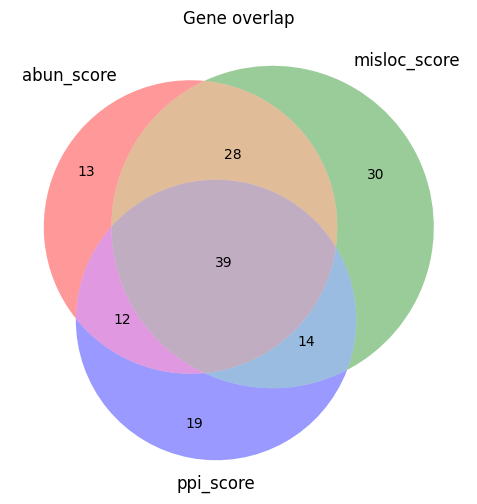

In [ ]:
# Check overlap between three assays

set_abun = set(scores.filter(pl.col("abun_score").is_not_null()).select("allele_0").to_series())
set_misloc = set(scores.filter(pl.col("misloc_score").is_not_null()).select("allele_0").to_series())
set_ppi = set(scores.filter(pl.col("ppi_score").is_not_null()).select("allele_0").to_series())

print(f"We profiled this many alleles in each assay: {len(set_abun)} for abundance, {len(set_misloc)} for mislocalization, and {len(set_ppi)} for ppi.")

plt.figure(figsize=(6, 6))
venn3([set_abun, set_misloc, set_ppi], ('abun_score', 'misloc_score', 'ppi_score'))
plt.title("Allele overlap")
plt.show()

set_abun = set(scores.filter(pl.col("abun_score").is_not_null()).select("symbol").to_series())
set_misloc = set(scores.filter(pl.col("misloc_score").is_not_null()).select("symbol").to_series())
set_ppi = set(scores.filter(pl.col("ppi_score").is_not_null()).select("symbol").to_series())

print(f"We profiled this many genes in each assay: {len(set_abun)} for abundance, {len(set_misloc)} for mislocalization, and {len(set_ppi)} for ppi.")

plt.figure(figsize=(6, 6))
venn3([set_abun, set_misloc, set_ppi], ('abun_score', 'misloc_score', 'ppi_score'))
plt.title("Gene overlap")
plt.show()

## Compare ClinVar label representation across assays

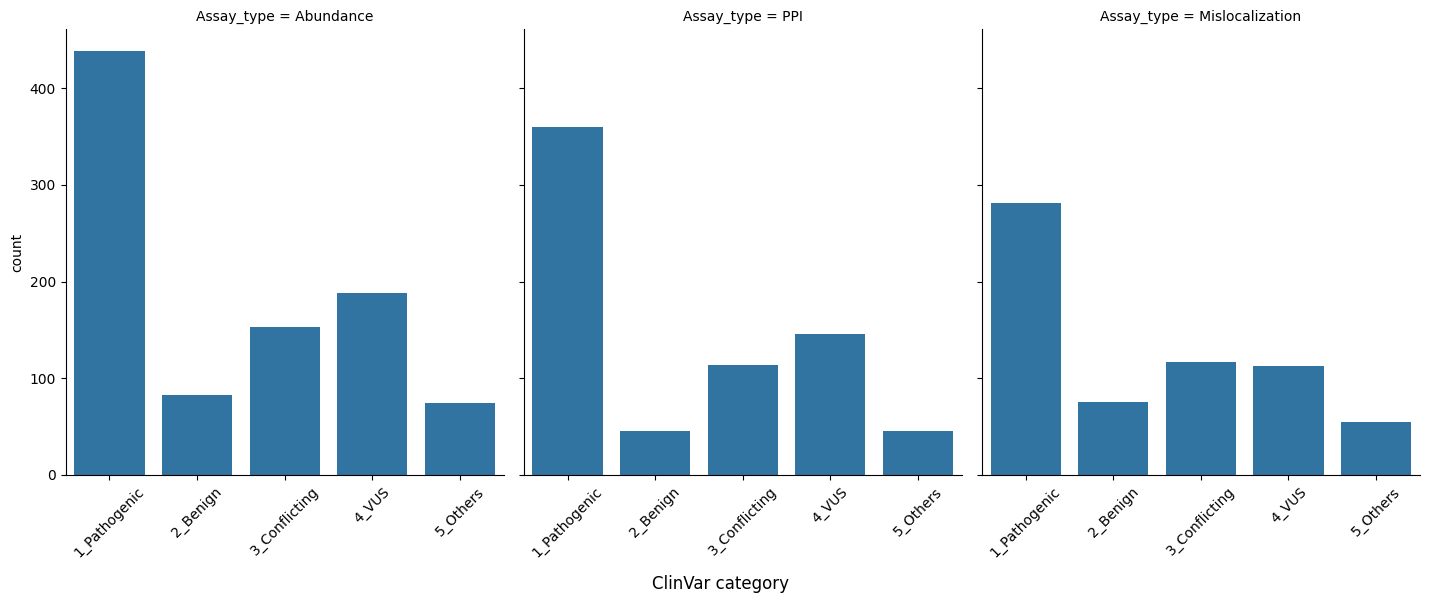

In [101]:
abun = scores.select(["clinvar_clnsig_clean", "abun_score"]).filter(
    ~pl.col("abun_score").is_null()
    ).select("clinvar_clnsig_clean").to_series().value_counts().sort("clinvar_clnsig_clean").with_columns(
        pl.lit("Abundance").alias("Assay_type")
    )

ppi = scores.select(["clinvar_clnsig_clean", "ppi_score"]).filter(
    ~pl.col("ppi_score").is_null()
    ).select("clinvar_clnsig_clean").to_series().value_counts().sort("clinvar_clnsig_clean").with_columns(
        pl.lit("PPI").alias("Assay_type")
    )

misloc = scores.select(["clinvar_clnsig_clean", "misloc_score"]).filter(
    ~pl.col("misloc_score").is_null()
    ).select("clinvar_clnsig_clean").to_series().value_counts().sort("clinvar_clnsig_clean").with_columns(
        pl.lit("Mislocalization").alias("Assay_type")
    )

bar_df = pl.concat([abun, ppi, misloc]).to_pandas()

g = sns.catplot(
    bar_df, kind="bar",
    x='clinvar_clnsig_clean', y='count', col="Assay_type",
    height=6, aspect=0.8,
)
g.set_xticklabels(rotation=45)

for ax in g.axes.flatten():
    ax.set_xlabel('')

g.fig.subplots_adjust(bottom=0.2)
g.fig.text(0.5, 0.01, "ClinVar category", ha="center", fontsize=12)
plt.show()

## How many variants are a hit in at least one assay?

In [ ]:
scores = scores.with_columns(
    (pl.col("abun_score") < -5).alias("abun_hit"),
    (pl.col("misloc_score") > 0.8).alias("misloc_hit"),
    (pl.col("ppi_score") > 0.6).alias("ppi_hit")
)


/var/folders/g0/nk06fpgs01z6zmr4x7kvp0g80000gp/T/ipykernel_3768/1743448681.py:4: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  scores_hm['abun_hit'] = scores_hm['abun_hit'].replace({True: 1, False: -1, np.nan: 0})
/var/folders/g0/nk06fpgs01z6zmr4x7kvp0g80000gp/T/ipykernel_3768/1743448681.py:5: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  scores_hm['misloc_hit'] = scores_hm['misloc_hit'].replace({True: 1, False: -1, np.nan: 0})
/var/folders/g0/nk06fpgs01z6zmr4x7kvp0g80000gp/T/ipykernel_3768/1743448681.py:6: FutureWarning: Downcast

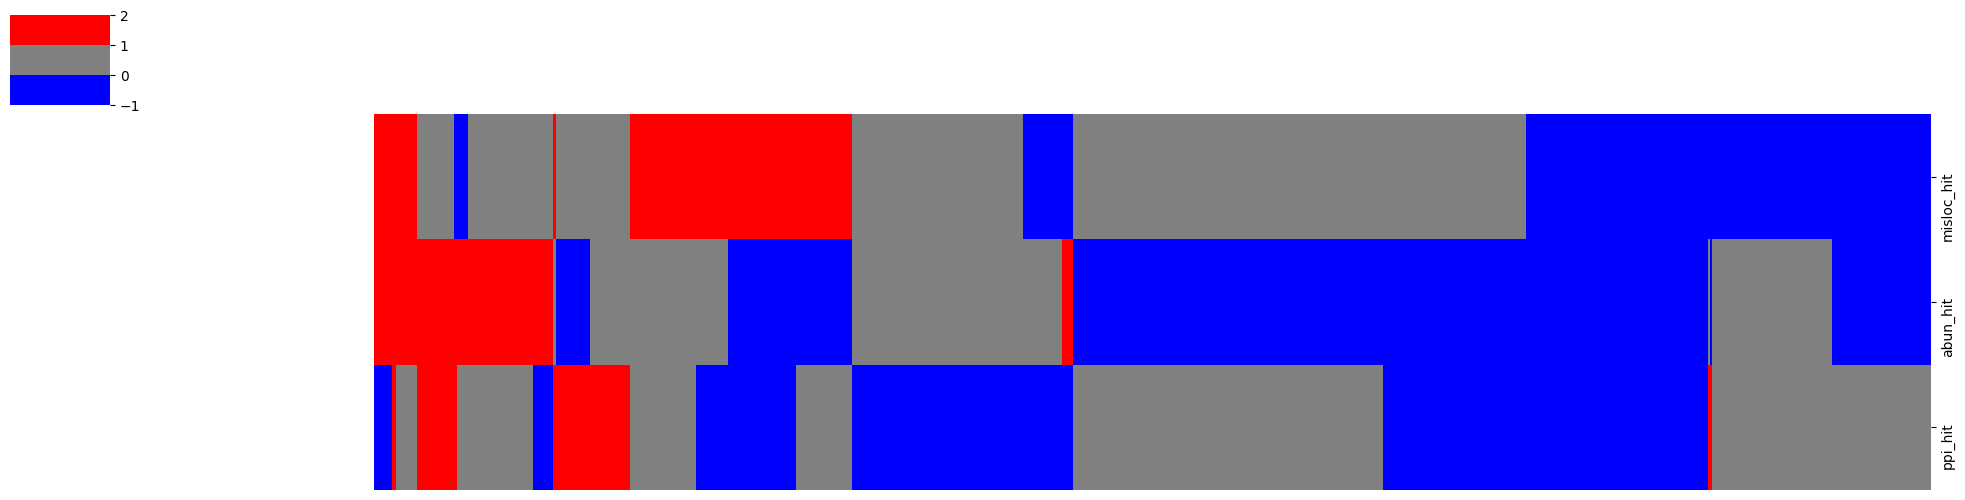

In [ ]:
scores_hm = scores.select(["abun_hit", "misloc_hit", "ppi_hit"]).to_pandas()
scores_hm['abun_hit'] = scores_hm['abun_hit'].replace({True: 1, False: -1, np.nan: 0})
scores_hm['misloc_hit'] = scores_hm['misloc_hit'].replace({True: 1, False: -1, np.nan: 0})
scores_hm['ppi_hit'] = scores_hm['ppi_hit'].replace({True: 1, False: -1, np.nan: 0})

cmap = colors.ListedColormap(['blue', 'grey', 'red'])
bounds = [-1, 0, 1, 2]
norm = colors.BoundaryNorm(bounds, cmap.N)

cg = sns.clustermap(scores_hm.transpose(), figsize=(20, 5), cmap=cmap, norm=norm, xticklabels=False)
cg.ax_row_dendrogram.set_visible(False)
cg.ax_col_dendrogram.set_visible(False)
plt.show()

/var/folders/g0/nk06fpgs01z6zmr4x7kvp0g80000gp/T/ipykernel_3768/3336534764.py:2: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  scores_hm['abun_hit'] = scores_hm['abun_hit'].replace({True: 1, False: -1, np.nan: 0})
/var/folders/g0/nk06fpgs01z6zmr4x7kvp0g80000gp/T/ipykernel_3768/3336534764.py:3: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  scores_hm['misloc_hit'] = scores_hm['misloc_hit'].replace({True: 1, False: -1, np.nan: 0})
/var/folders/g0/nk06fpgs01z6zmr4x7kvp0g80000gp/T/ipykernel_3768/3336534764.py:4: FutureWarning: Downcast

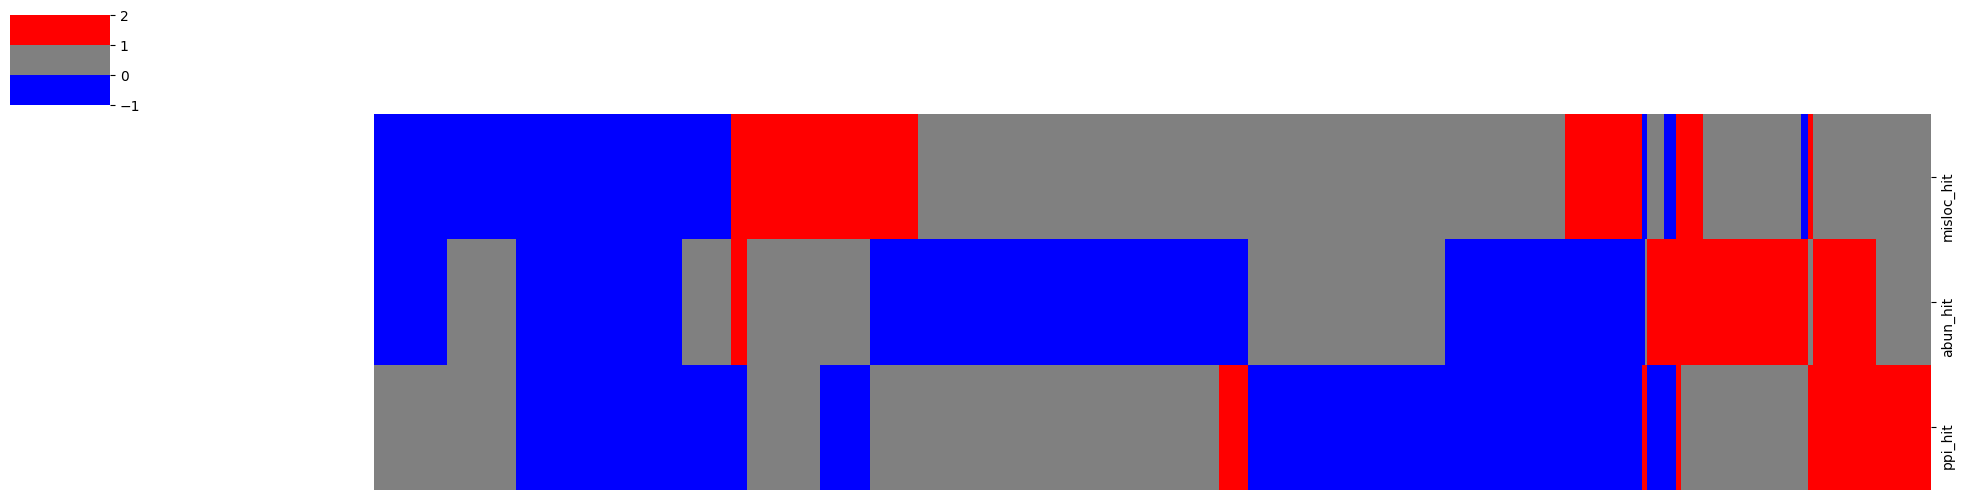

In [125]:
scores_hm = scores.filter(pl.col("clinvar_clnsig_clean") == "1_Pathogenic").select(["abun_hit", "misloc_hit", "ppi_hit"]).to_pandas()
scores_hm['abun_hit'] = scores_hm['abun_hit'].replace({True: 1, False: -1, np.nan: 0})
scores_hm['misloc_hit'] = scores_hm['misloc_hit'].replace({True: 1, False: -1, np.nan: 0})
scores_hm['ppi_hit'] = scores_hm['ppi_hit'].replace({True: 1, False: -1, np.nan: 0})

cmap = colors.ListedColormap(['blue', 'grey', 'red'])
bounds = [-1, 0, 1, 2]
norm = colors.BoundaryNorm(bounds, cmap.N)

cg = sns.clustermap(scores_hm.transpose(), figsize=(20, 5), cmap=cmap, norm=norm, xticklabels=False)
cg.ax_row_dendrogram.set_visible(False)
cg.ax_col_dendrogram.set_visible(False)
plt.show()

/var/folders/g0/nk06fpgs01z6zmr4x7kvp0g80000gp/T/ipykernel_3768/2595780987.py:2: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  scores_hm['abun_hit'] = scores_hm['abun_hit'].replace({True: 1, False: -1, np.nan: 0})
/var/folders/g0/nk06fpgs01z6zmr4x7kvp0g80000gp/T/ipykernel_3768/2595780987.py:3: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  scores_hm['misloc_hit'] = scores_hm['misloc_hit'].replace({True: 1, False: -1, np.nan: 0})
/var/folders/g0/nk06fpgs01z6zmr4x7kvp0g80000gp/T/ipykernel_3768/2595780987.py:4: FutureWarning: Downcast

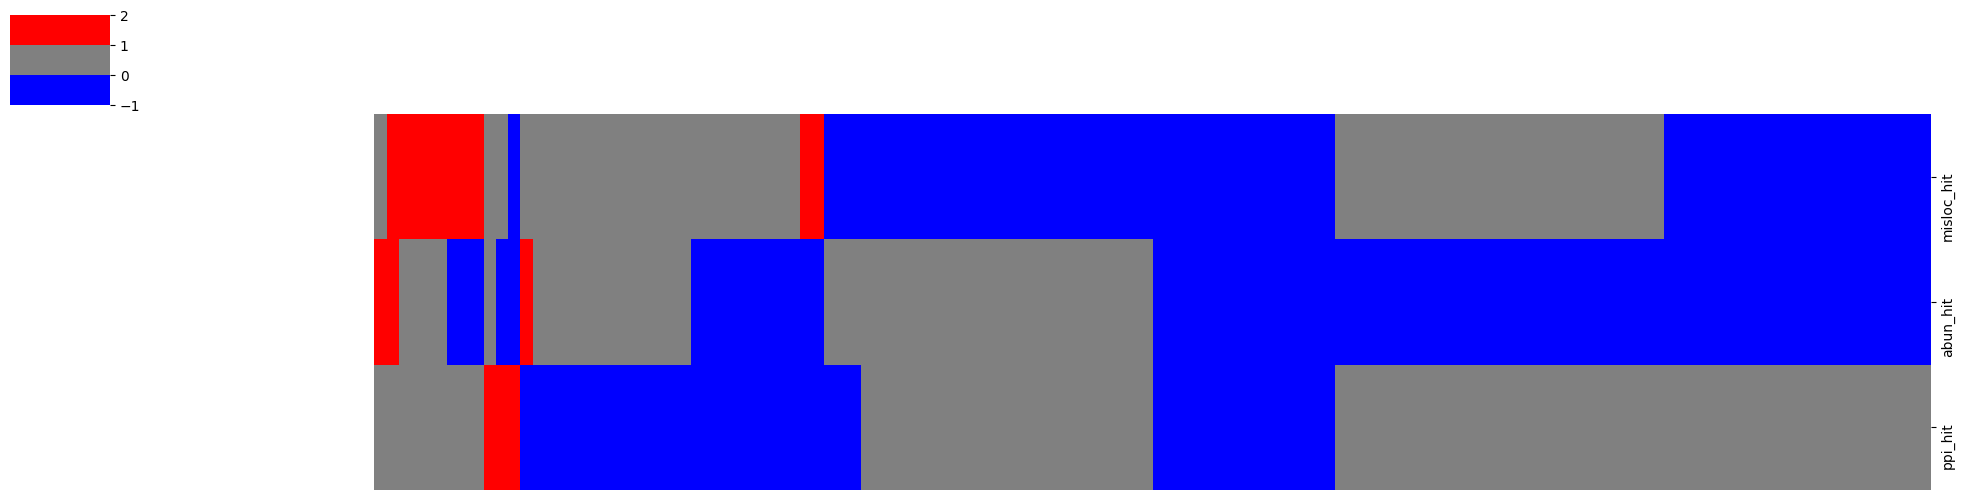

In [126]:
scores_hm = scores.filter(pl.col("clinvar_clnsig_clean") == "2_Benign").select(["abun_hit", "misloc_hit", "ppi_hit"]).to_pandas()
scores_hm['abun_hit'] = scores_hm['abun_hit'].replace({True: 1, False: -1, np.nan: 0})
scores_hm['misloc_hit'] = scores_hm['misloc_hit'].replace({True: 1, False: -1, np.nan: 0})
scores_hm['ppi_hit'] = scores_hm['ppi_hit'].replace({True: 1, False: -1, np.nan: 0})

cmap = colors.ListedColormap(['blue', 'grey', 'red'])
bounds = [-1, 0, 1, 2]
norm = colors.BoundaryNorm(bounds, cmap.N)

cg = sns.clustermap(scores_hm.transpose(), figsize=(20, 5), cmap=cmap, norm=norm, xticklabels=False)
cg.ax_row_dendrogram.set_visible(False)
cg.ax_col_dendrogram.set_visible(False)
plt.show()

/var/folders/g0/nk06fpgs01z6zmr4x7kvp0g80000gp/T/ipykernel_3768/3408531620.py:2: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  scores_hm['abun_hit'] = scores_hm['abun_hit'].replace({True: 1, False: -1, np.nan: 0})
/var/folders/g0/nk06fpgs01z6zmr4x7kvp0g80000gp/T/ipykernel_3768/3408531620.py:3: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  scores_hm['misloc_hit'] = scores_hm['misloc_hit'].replace({True: 1, False: -1, np.nan: 0})
/var/folders/g0/nk06fpgs01z6zmr4x7kvp0g80000gp/T/ipykernel_3768/3408531620.py:4: FutureWarning: Downcast

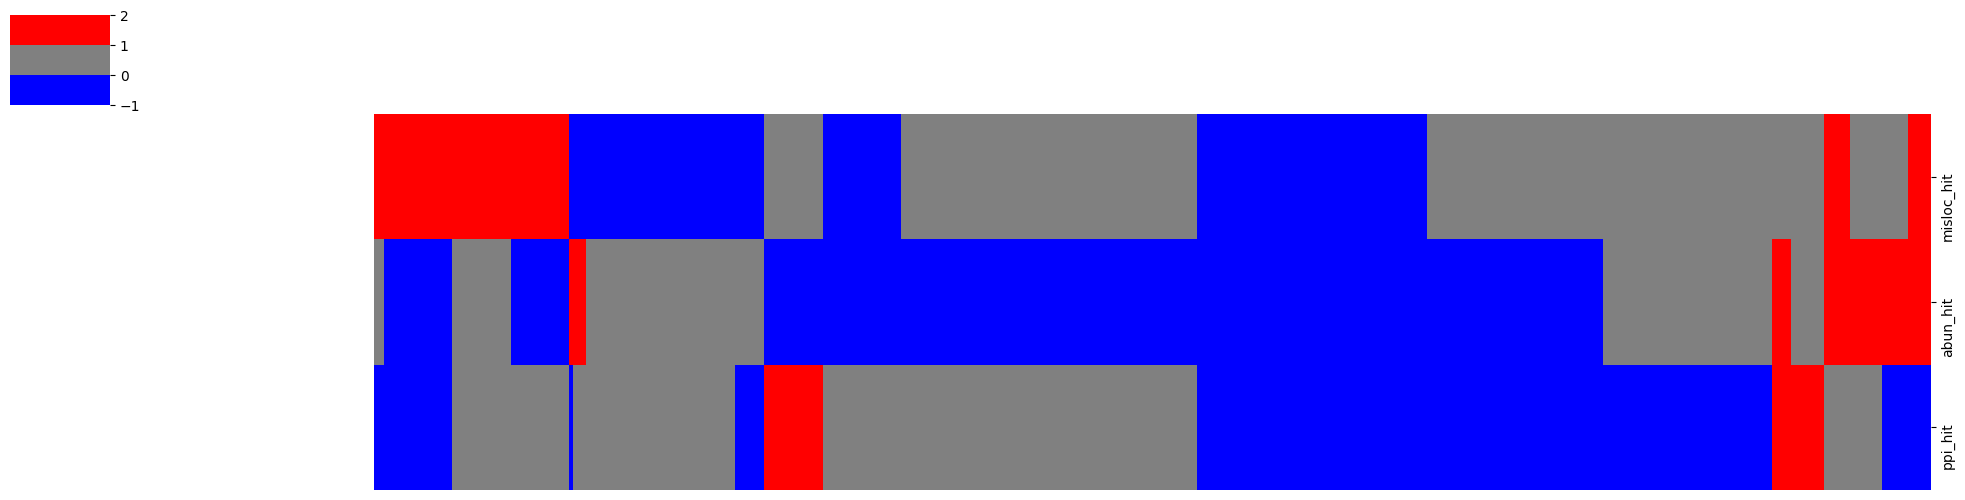

In [127]:
scores_hm = scores.filter((pl.col("clinvar_clnsig_clean") == "3_Conflicting") | (pl.col("clinvar_clnsig_clean") == "4_VUS")).select(["abun_hit", "misloc_hit", "ppi_hit"]).to_pandas()
scores_hm['abun_hit'] = scores_hm['abun_hit'].replace({True: 1, False: -1, np.nan: 0})
scores_hm['misloc_hit'] = scores_hm['misloc_hit'].replace({True: 1, False: -1, np.nan: 0})
scores_hm['ppi_hit'] = scores_hm['ppi_hit'].replace({True: 1, False: -1, np.nan: 0})

cmap = colors.ListedColormap(['blue', 'grey', 'red'])
bounds = [-1, 0, 1, 2]
norm = colors.BoundaryNorm(bounds, cmap.N)

cg = sns.clustermap(scores_hm.transpose(), figsize=(20, 5), cmap=cmap, norm=norm, xticklabels=False)
cg.ax_row_dendrogram.set_visible(False)
cg.ax_col_dendrogram.set_visible(False)
plt.show()

## Compare readouts across assays

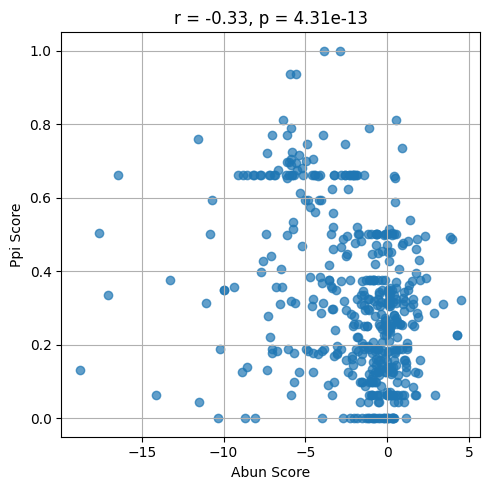

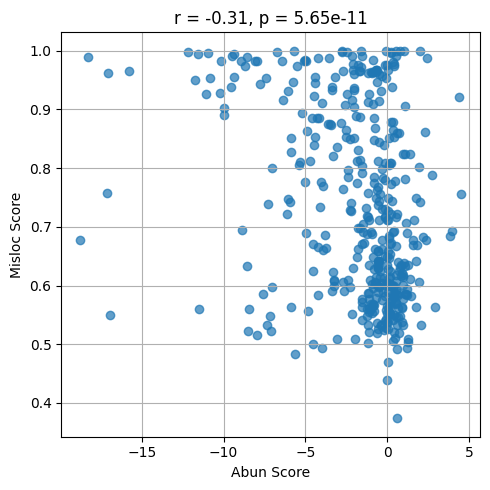

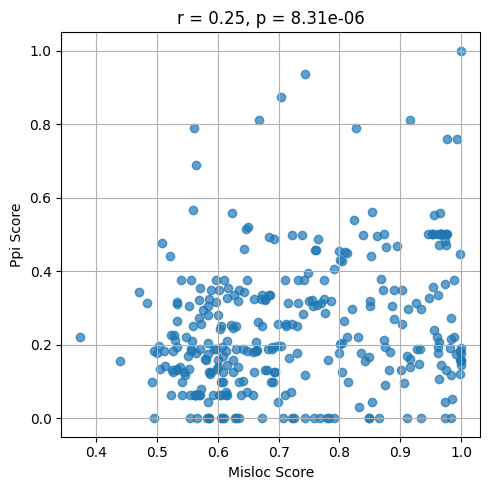

In [102]:
plot_pairs = [
    ("abun_score", "ppi_score"),
    ("abun_score", "misloc_score"),
    ("misloc_score", "ppi_score"),
]

df = scores.to_pandas()

# Plot each pair with correlation info
for x_col, y_col in plot_pairs:
    x = df[x_col]
    y = df[y_col]

    # Drop rows with missing values in either column
    mask = x.notna() & y.notna()
    x_clean = x[mask]
    y_clean = y[mask]

    # Calculate correlation
    r, p = pearsonr(x_clean, y_clean)

    # Plot
    plt.figure(figsize=(5,5))
    plt.scatter(x_clean, y_clean, alpha=0.7)
    plt.xlabel(x_col.replace('_', ' ').title())
    plt.ylabel(y_col.replace('_', ' ').title())
    plt.title(f"r = {r:.2f}, p = {p:.2e}")
    plt.grid(True)
    plt.tight_layout()
    plt.show()


In [ ]:
# Considering pathogenic variants - how many are a hit in at least one assay? Same question for other categories.

# Add AI scores, plddt, and rsa to the integrative inputs folder

# Try find a subset of alleles based on prior knowledge that we expect to have higher or lower correlation acorss specific assays
# Look at variants that are hits in both PPI and mislocalization but not strongly abundance - are the lost interactions involved in transport? Or specific to the previously located cellular compartment?

## Add AI scores and sequence characteristics

In [ ]:
ai = pl.DataFrame(pd.read_csv(f"{inputs_dir}/ai_pred_struc_scores.tsv", sep="\t", low_memory=False))

keep_cols = [
    "PROVEAN_converted_rankscore",
    "ESM1b_rankscore",
    "AlphaMissense_rankscore"
]